# Decoding the Rhythms of Emotion: A Sentimental Journey Through Music Genres
## Notebook 3 of 5 — Genre Identification

**Text Mining 2026/2027 | Group XX**

Raya Daher Alkhatib (20241416), Danyial Ahmad (20241831), Shaahir Racharla (20241419), Pedro Ambar (20231709)

| Notebook | Content |
|---|---|
| `01_eda` | Abstract, Introduction and Data Exploration |
| `02_preprocessing` | Initial Data Preprocessing |
| **`03_genre_classification`** | **Genre Identification** |
| `04_sentiment_analysis` | Sentiment Analysis |
| `05_conclusion_annexes` | Conclusion and Annexes |

**Run order:** `01 → 02 → 03 → 04 → 05`

Notebook 2 produces the cleaned datasets used in this notebook. Raw data are stored in `data/raw/`, while the processed datasets are stored in `data/processed/`.

The modelling decisions in this notebook build on the preprocessing and exploratory findings from the previous notebooks.

## Objective

The objective of this notebook is to predict the musical genre of each song from its lyrics.

This is a **multiclass single-label text classification problem** with six possible genres: `country`, `misc`, `pop`, `rap`, `rb`, and `rock`.

The modelling strategy follows five stages:

1. establish a baseline and compare classical text classifiers;
2. assess the effect of class imbalance;
3. evaluate additional preprocessing and feature-selection decisions;
4. improve the textual representation and tune the strongest classifier;
5. confirm the final configuration using cross-validation and an untouched holdout set before producing the Kaggle submission.

**Macro F1** is the primary evaluation metric because it gives equal importance to every genre despite the strong class imbalance. Accuracy and class-level metrics are reported as complementary diagnostics.

Only information derived from the lyrics is used in the final classifier. Descriptive metadata such as artist identity is deliberately excluded from the final model because the project objective is to predict genre **from song lyrics**.

**Report section:** III. Genre Identification — additional preprocessing, feature selection, modelling strategy, model assessment and performance evaluation.

| | |
|---|---|
| **Inputs** | `data/train_clean.pkl, data/test_clean.pkl` |
| **Outputs** | `submissions/GroupXX_VersionNN.csv`, `results/` |
| **Run order** | `01` → `02` → `03` → `04` → `05` |

### Imports and Setup

In [30]:
%run ./_setup.py

import gc
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS,
)

from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

def hstack_csr(left, right):
    return sparse.hstack(
        [left, right],
        format="csr"
    )

Repo root: C:\Users\pedro\Desktop\Text Mining\Music-Genre-Identification | seed: 42


## 1. Data preparation

Notebook 2 already performed the initial text cleaning. This notebook therefore starts from the processed lyrics and focuses on additional feature extraction and predictive modelling.

Besides the cleaned text, a small set of **lyrics-derived structural features** is constructed. These features describe properties such as song length, number of lines, lexical diversity, and the presence of section markers.

They do not use artist identity, popularity, year, or any other external metadata.

In [2]:
train = pd.read_pickle(
    config.PROCESSED_DIR / "train_clean.pkl"
)[["id", "clean", "raw_text", "n_words", "tag"]].copy()

test = pd.read_pickle(
    config.PROCESSED_DIR / "test_clean.pkl"
)[["id", "clean", "raw_text", "n_words"]].copy()


def lexical_diversity(text):
    tokens = text.split()

    if len(tokens) == 0:
        return 0.0

    return len(set(tokens)) / len(tokens)


def add_lyric_structure(df):
    out = df.copy()

    clean = out["clean"].fillna("")
    raw = out["raw_text"].fillna("")

    line_count = raw.str.count("\n") + 1
    line_count = line_count.where(raw.str.len() > 0, 0)

    section_count = clean.str.count(r"\bsec_\w+\b")

    out["log_words"] = np.log1p(
        out["n_words"].fillna(0).astype(float)
    )

    out["log_lines"] = np.log1p(
        line_count.astype(float)
    )

    out["ttr"] = clean.map(
        lexical_diversity
    )

    out["short_song"] = (
        out["n_words"].fillna(0) < 50
    ).astype(float)

    out["has_sections"] = (
        section_count > 0
    ).astype(float)

    out["log_section_tokens"] = np.log1p(
        section_count.astype(float)
    )

    out["clean_no_sections"] = (
        clean
        .str.replace(
            r"\bsec_\w+\b",
            " ",
            regex=True
        )
        .str.replace(
            r"\s+",
            " ",
            regex=True
        )
        .str.strip()
    )

    return out


train = add_lyric_structure(train)
test = add_lyric_structure(test)

STRUCTURAL_COLUMNS = [
    "log_words",
    "log_lines",
    "ttr",
    "short_song",
    "has_sections",
    "log_section_tokens",
]

print("Train:", train.shape)
print("Test:", test.shape)
print("Genres:", sorted(train["tag"].unique()))

Train: (134789, 12)
Test: (33742, 11)
Genres: ['country', 'misc', 'pop', 'rap', 'rb', 'rock']


## 2. Validation strategy

Three levels of validation are used.

**Screening sample.** A stratified sample of 40,000 songs is used for relatively inexpensive comparisons between preprocessing choices, representations and models.

**Development data.** After the strongest configuration is identified, it is confirmed using 5-fold stratified cross-validation on the full development set.

**Final holdout.** Twenty percent of the labelled data are kept completely outside model selection. This holdout set is used only once, after the representation and hyperparameters have been fixed.

The official Kaggle test set is never used for model selection.

In [3]:
dev_df, holdout_df = train_test_split(
    train,
    test_size=0.20,
    random_state=config.SEED,
    stratify=train["tag"],
)

screen_df, _ = train_test_split(
    dev_df,
    train_size=40_000,
    random_state=config.SEED,
    stratify=dev_df["tag"],
)

screen_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=config.SEED,
)

confirm_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=config.SEED,
)

print("Development set:", len(dev_df))
print("Final holdout:", len(holdout_df))
print("Screening sample:", len(screen_df))

Development set: 107831
Final holdout: 26958
Screening sample: 40000


## 3. Reproducible feature pipelines

Text vectorizers and numerical scalers are placed inside Scikit-Learn pipelines.

This ensures that, during cross-validation, the vocabulary, IDF values and scaling parameters are learned only from each training fold and then applied to its corresponding validation fold.

Two main text representations are considered:

- word-level TF-IDF using unigrams and bigrams;
- character-level TF-IDF using character n-grams.

Structural features can optionally be appended to the textual representation.

In [4]:
def make_word_features(
    text_col="clean",
    sublinear_tf=False,
    include_structural=False,
    include_char=False,
    stop_words=None,
    min_df=10,
    ngram_range=(1, 2),
):
    transformers = [
        (
            "word",
            TfidfVectorizer(
                token_pattern=r"(?u)\b\w+\b",
                ngram_range=ngram_range,
                min_df=min_df,
                sublinear_tf=sublinear_tf,
                stop_words=stop_words,
            ),
            text_col,
        )
    ]

    if include_char:
        transformers.append(
            (
                "char",
                TfidfVectorizer(
                    analyzer="char_wb",
                    ngram_range=(3, 5),
                    min_df=10,
                    max_features=250_000,
                ),
                text_col,
            )
        )

    if include_structural:
        transformers.append(
            (
                "structure",
                MinMaxScaler(),
                STRUCTURAL_COLUMNS,
            )
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=1.0,
    )


def make_bow_features():
    return ColumnTransformer(
        [
            (
                "bow",
                CountVectorizer(
                    token_pattern=r"(?u)\b\w+\b",
                    ngram_range=(1, 1),
                    min_df=2,
                ),
                "clean",
            )
        ],
        remainder="drop",
    )


def cv_summary(name, estimator, X, y, cv):
    scores = cross_validate(
        estimator,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro",
        },
        n_jobs=1,
    )

    return {
        "model": name,
        "accuracy": scores["test_accuracy"].mean(),
        "macro_f1": scores["test_macro_f1"].mean(),
        "macro_f1_std": scores["test_macro_f1"].std(),
    }

## 4. Initial model screening

A `DummyClassifier` is used as a baseline to verify that the predictive models learn information beyond the class distribution.

Three standard text-classification algorithms are then compared:

- Multinomial Naive Bayes;
- Logistic Regression;
- Linear Support Vector Machine.

Multinomial Naive Bayes receives a Bag-of-Words representation, while Logistic Regression and Linear SVM receive word-level TF-IDF.

The Linear SVM performs multiclass prediction using a One-vs-Rest strategy: one decision function is learned for each genre and the genre with the highest decision score is selected.

In [5]:
screen_y = screen_df["tag"]

model_results = []

dummy_result = cv_summary(
    "Dummy — most frequent",
    DummyClassifier(
        strategy="most_frequent"
    ),
    screen_df[["log_words"]],
    screen_y,
    screen_cv,
)

model_results.append(dummy_result)


models = {
    "Multinomial NB + BoW": Pipeline([
        (
            "features",
            make_bow_features()
        ),
        (
            "classifier",
            MultinomialNB(
                alpha=1.0
            )
        ),
    ]),

    "Logistic Regression + TF-IDF": Pipeline([
        (
            "features",
            make_word_features()
        ),
        (
            "classifier",
            LogisticRegression(
                solver="saga",
                max_iter=1000,
                random_state=config.SEED,
            )
        ),
    ]),

    "Linear SVM + TF-IDF": Pipeline([
        (
            "features",
            make_word_features()
        ),
        (
            "classifier",
            LinearSVC(
                C=1.0,
                random_state=config.SEED,
            )
        ),
    ]),
}


for name, model in models.items():
    model_results.append(
        cv_summary(
            name,
            model,
            screen_df,
            screen_y,
            screen_cv,
        )
    )


model_results = (
    pd.DataFrame(model_results)
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .reset_index(drop=True)
)

model_results.round(4)

,model,accuracy,macro_f1,macro_f1_std
0,Multinomial NB + BoW,0.5939,0.4525,0.0048
1,Linear SVM + TF-IDF,0.6438,0.4477,0.0091
2,Logistic Regression + TF-IDF,0.6594,0.4186,0.0049
3,Dummy — most frequent,0.4125,0.0973,0.0000


### Initial screening results

All three supervised models substantially outperform the Dummy baseline, confirming that the lyrics contain useful information for genre prediction.

The models nevertheless show different trade-offs. Logistic Regression achieves the highest overall accuracy, whereas Multinomial Naive Bayes obtains the highest Macro F1 in this initial screening. Linear SVM lies between the two.

Because Macro F1 gives equal weight to every genre, this discrepancy suggests that the linear models may be favouring the more frequent classes. Before selecting a modelling family, we therefore evaluate whether explicitly accounting for class imbalance changes this comparison.

## 5. Class imbalance

The genre distribution is substantially imbalanced. Accuracy can therefore be dominated by the most frequent genres even when the model performs poorly on minority classes.

For the two linear classifiers, we compare the default objective against `class_weight="balanced"`. This option increases the importance of observations belonging to less frequent classes during training.

Multinomial Naive Bayes is retained as a reference because it achieved the strongest Macro F1 in the initial screening.

The objective of this experiment is to determine whether the lower Macro F1 of the linear models is partly explained by class imbalance.

In [6]:
# imbalance_models = {
#     "Multinomial NB + BoW": Pipeline([
#         (
#             "features",
#             make_bow_features()
#         ),
#         (
#             "classifier",
#             MultinomialNB(
#                 alpha=1.0
#             )
#         ),
#     ]),

#     "Logistic Regression — unbalanced": Pipeline([
#         (
#             "features",
#             make_word_features()
#         ),
#         (
#             "classifier",
#             LogisticRegression(
#                 max_iter=1000,
#                 random_state=config.SEED,
#             )
#         ),
#     ]),

#     "Logistic Regression — balanced": Pipeline([
#         (
#             "features",
#             make_word_features()
#         ),
#         (
#             "classifier",
#             LogisticRegression(
#                 class_weight="balanced",
#                 max_iter=1000,
#                 random_state=config.SEED,
#             )
#         ),
#     ]),

#     "Linear SVM — unbalanced": Pipeline([
#         (
#             "features",
#             make_word_features()
#         ),
#         (
#             "classifier",
#             LinearSVC(
#                 C=1.0,
#                 random_state=config.SEED,
#             )
#         ),
#     ]),

#     "Linear SVM — balanced": Pipeline([
#         (
#             "features",
#             make_word_features()
#         ),
#         (
#             "classifier",
#             LinearSVC(
#                 C=1.0,
#                 class_weight="balanced",
#                 random_state=config.SEED,
#             )
#         ),
#     ]),
# }


# imbalance_results = []


# for name, model in imbalance_models.items():

#     result = cv_summary(
#         name,
#         model,
#         screen_df,
#         screen_y,
#         screen_cv,
#     )

#     imbalance_results.append(
#         result
#     )


# imbalance_results = (
#     pd.DataFrame(
#         imbalance_results
#     )
#     .sort_values(
#         "macro_f1",
#         ascending=False
#     )
#     .reset_index(drop=True)
# )


# imbalance_results.round(4)

### Effect of class weighting

*This experiment was run during model development. The code is retained in the notebook for transparency but is commented out in the final executable version.*

Applying balanced class weights substantially improves Macro F1 for both linear models, although overall accuracy decreases.

For Logistic Regression, Macro F1 increases from **0.4185 to 0.4924**, while for Linear SVM it increases from **0.4477 to 0.4837**.

This trade-off is expected in an imbalanced multiclass problem: the unweighted models obtain higher accuracy by favouring the dominant genres, whereas balanced training assigns more importance to mistakes on minority classes.

Logistic Regression currently achieves the highest Macro F1. To understand this improvement in more detail, we compare its class-level F1 scores before and after balancing.

In [7]:
# lr_unbalanced = Pipeline([
#     (
#         "features",
#         make_word_features()
#     ),
#     (
#         "classifier",
#         LogisticRegression(
#             max_iter=1000,
#             random_state=config.SEED,
#         )
#     ),
# ])


# lr_balanced = Pipeline([
#     (
#         "features",
#         make_word_features()
#     ),
#     (
#         "classifier",
#         LogisticRegression(
#             class_weight="balanced",
#             max_iter=1000,
#             random_state=config.SEED,
#         )
#     ),
# ])


# pred_unbalanced = cross_val_predict(
#     lr_unbalanced,
#     screen_df,
#     screen_y,
#     cv=screen_cv,
#     n_jobs=1,
# )

# pred_balanced = cross_val_predict(
#     lr_balanced,
#     screen_df,
#     screen_y,
#     cv=screen_cv,
#     n_jobs=1,
# )


# report_unbalanced = classification_report(
#     screen_y,
#     pred_unbalanced,
#     labels=config.LABELS,
#     output_dict=True,
#     zero_division=0,
# )

# report_balanced = classification_report(
#     screen_y,
#     pred_balanced,
#     labels=config.LABELS,
#     output_dict=True,
#     zero_division=0,
# )


# class_weight_comparison = pd.DataFrame({
#     "Unbalanced F1": [
#         report_unbalanced[label]["f1-score"]
#         for label in config.LABELS
#     ],
#     "Balanced F1": [
#         report_balanced[label]["f1-score"]
#         for label in config.LABELS
#     ],
# }, index=config.LABELS)


# class_weight_comparison["Difference"] = (
#     class_weight_comparison["Balanced F1"]
#     - class_weight_comparison["Unbalanced F1"]
# )


# class_weight_comparison.round(3)

### Class-level interpretation

*This diagnostic experiment was run during model development. The code is retained for transparency but is commented out in the final executable notebook.*

The class-level results confirm that the increase in Macro F1 is driven primarily by better performance on the underrepresented genres.

Balanced training substantially increases F1 for `country` (0.017 → 0.274), `rb` (0.090 → 0.275), and `rock` (0.321 → 0.461). Performance for `misc` also improves slightly.

In contrast, `pop` decreases from 0.699 to 0.559 and `rap` remains comparatively stable (0.844 → 0.834).

This illustrates the trade-off between overall accuracy and balanced performance across classes. Since Macro F1 gives equal importance to every genre, balanced training is preferred for the subsequent experiments.

## 6. Additional preprocessing

Two preprocessing decisions from Notebook 2 are tested empirically:

1. keeping stopwords;
2. keeping the section tokens created from tags such as `[Hook]`, `[Chorus]`, and `[Verse]`.

Each alternative changes only one element of the reference pipeline. This controlled comparison makes it possible to attribute any performance difference to the preprocessing decision itself.

The balanced Logistic Regression model is used as the reference classifier because it achieved the strongest Macro F1 in the previous screening stage.

In [8]:
# preprocessing_variants = {
#     "Reference": make_word_features(),

#     "Stopwords removed": make_word_features(
#         stop_words=list(
#             ENGLISH_STOP_WORDS
#         )
#     ),

#     "Section tokens removed": make_word_features(
#         text_col="clean_no_sections"
#     ),
# }


# preprocessing_results = []


# for name, features in preprocessing_variants.items():

#     model = Pipeline([
#         (
#             "features",
#             features
#         ),
#         (
#             "classifier",
#             LogisticRegression(
#                 class_weight="balanced",
#                 max_iter=1000,
#                 random_state=config.SEED,
#             )
#         ),
#     ])

#     result = cv_summary(
#         name,
#         model,
#         screen_df,
#         screen_y,
#         screen_cv,
#     )

#     preprocessing_results.append(
#         result
#     )


# preprocessing_results = (
#     pd.DataFrame(
#         preprocessing_results
#     )
#     .sort_values(
#         "macro_f1",
#         ascending=False
#     )
#     .reset_index(drop=True)
# )


# preprocessing_results.round(4)

### Preprocessing decision

*This experiment was run during model development. The code is retained for transparency but is commented out in the final executable notebook.*

The reference representation achieves the highest Macro F1 (**0.4924**).

Removing section tokens decreases Macro F1 to **0.4837**, while removing stopwords reduces it further to **0.4775**.

These results indicate that both types of information contribute to genre classification. Frequently occurring function words may still contain stylistic information in song lyrics, while structural markers such as `sec_chorus`, `sec_hook`, and `sec_verse` provide useful genre-related signals.

Therefore, both stopwords and section tokens are retained in all subsequent models.

## 7. Feature selection

The unigram and bigram TF-IDF representation creates a high-dimensional feature space.

Although `min_df=10` already removes very rare terms, an additional supervised feature-selection step is evaluated using the chi-square statistic.

Chi-square measures the association between each textual feature and the target genre. `SelectKBest` retains only the features with the strongest association with the class labels.

Feature selection is performed inside the cross-validation pipeline, ensuring that the validation fold does not influence which features are selected.

In [9]:
# feature_selection_results = []


# for k in [
#     10_000,
#     25_000,
#     50_000,
#     "all",
# ]:

#     model = Pipeline([
#         (
#             "features",
#             make_word_features()
#         ),
#         (
#             "selection",
#             SelectKBest(
#                 score_func=chi2,
#                 k=k
#             )
#         ),
#         (
#             "classifier",
#             LogisticRegression(
#                 class_weight="balanced",
#                 max_iter=1000,
#                 random_state=config.SEED,
#             )
#         ),
#     ])

#     result = cv_summary(
#         f"k={k}",
#         model,
#         screen_df,
#         screen_y,
#         screen_cv,
#     )

#     feature_selection_results.append(
#         result
#     )


# feature_selection_results = (
#     pd.DataFrame(
#         feature_selection_results
#     )
#     .sort_values(
#         "macro_f1",
#         ascending=False
#     )
#     .reset_index(drop=True)
# )


# feature_selection_results.round(4)

### Feature-selection decision

*This experiment was run during model development. The code is retained for transparency but is commented out in the final executable notebook.*

The complete TF-IDF feature set achieves the highest Macro F1 (**0.4924**) among the tested configurations.

Restricting the representation to the 50,000 highest-ranked chi-square features reduces Macro F1 to **0.4883**, with larger decreases when only 25,000 or 10,000 features are retained.

This indicates that features with weaker individual associations still contribute useful information when combined by the classifier.

Therefore, `SelectKBest` is not included in the final model. The existing `min_df=10` threshold remains the vocabulary filter used to remove extremely rare terms.

## 8. Improving the text representation

The previous experiments established the preprocessing decisions and the reference classifier. We now investigate whether the numerical representation of the lyrics can be improved.

Two extensions are evaluated first:

**Sublinear term frequency.** Song lyrics often contain repeated words, refrains and choruses. With standard TF-IDF, repeated occurrences continue increasing term frequency. Setting `sublinear_tf=True` replaces raw term-frequency growth with logarithmic growth, reducing the influence of extreme repetition.

**Structural features.** Genre may also be reflected in characteristics that are not directly captured by TF-IDF, such as song length, number of lines, lexical diversity, and the presence of section markers.

Because Logistic Regression currently provides the strongest Macro F1 while Linear SVM has also shown competitive performance, both classifiers are evaluated under the same representations.

Hyperparameters are intentionally kept fixed at this stage so that performance differences can be attributed to the representation rather than to model tuning.

In [10]:
# representation_configs = {
#     "Standard word TF-IDF": {
#         "sublinear_tf": False,
#         "include_structural": False,
#     },

#     "Sublinear word TF-IDF": {
#         "sublinear_tf": True,
#         "include_structural": False,
#     },

#     "Standard word + structural": {
#         "sublinear_tf": False,
#         "include_structural": True,
#     },

#     "Sublinear word + structural": {
#         "sublinear_tf": True,
#         "include_structural": True,
#     },
# }


# classifiers = {
#     "Logistic Regression": LogisticRegression(
#         class_weight="balanced",
#         max_iter=1000,
#         random_state=config.SEED,
#     ),

#     "Linear SVM": LinearSVC(
#         C=1.0,
#         class_weight="balanced",
#         random_state=config.SEED,
#     ),
# }


# representation_results = []


# for representation_name, settings in representation_configs.items():

#     for classifier_name, classifier in classifiers.items():

#         model = Pipeline([
#             (
#                 "features",
#                 make_word_features(
#                     sublinear_tf=settings[
#                         "sublinear_tf"
#                     ],
#                     include_structural=settings[
#                         "include_structural"
#                     ],
#                 )
#             ),
#             (
#                 "classifier",
#                 classifier
#             ),
#         ])

#         result = cv_summary(
#             f"{classifier_name} | {representation_name}",
#             model,
#             screen_df,
#             screen_y,
#             screen_cv,
#         )

#         representation_results.append(
#             result
#         )


# representation_results = (
#     pd.DataFrame(
#         representation_results
#     )
#     .sort_values(
#         "macro_f1",
#         ascending=False
#     )
#     .reset_index(drop=True)
# )


# representation_results.round(4)

### Representation decision

*This experiment was run during model development. The code is retained for transparency but is commented out in the final executable notebook.*

Sublinear term frequency provides the largest improvement over the original word-level TF-IDF representation.

For Logistic Regression, Macro F1 increases from **0.4924** with standard TF-IDF to **0.5174** with sublinear TF. Adding lyrics-derived structural features provides a further improvement to **0.5205**.

The same general pattern is observed for Linear SVM: Macro F1 increases from **0.4837** with standard TF-IDF to **0.5022** with sublinear TF and to **0.5090** when structural features are also included.

Logistic Regression remains the strongest classifier at this stage.

The selected representation is therefore **sublinear word TF-IDF combined with structural features**. Character-level n-grams are tested next to determine whether they provide additional information beyond this representation.

### Character-level information

Word n-grams capture complete words and short word sequences, but they may miss stylistic information contained within words.

Character n-grams can capture subword patterns such as contractions, spelling variants, slang, suffixes, and informal expressions that may differ between musical genres.

To isolate their contribution, character n-grams are added to the current best representation — sublinear word TF-IDF plus structural features — while keeping the classifiers unchanged.

In [11]:
# character_results = []


# for classifier_name, classifier in {
#     "Logistic Regression": LogisticRegression(
#         class_weight="balanced",
#         max_iter=1000,
#         random_state=config.SEED,
#     ),

#     "Linear SVM": LinearSVC(
#         C=1.0,
#         class_weight="balanced",
#         random_state=config.SEED,
#     ),
# }.items():

#     model = Pipeline([
#         (
#             "features",
#             make_word_features(
#                 sublinear_tf=True,
#                 include_structural=True,
#                 include_char=True,
#             )
#         ),
#         (
#             "classifier",
#             classifier
#         ),
#     ])

#     result = cv_summary(
#         f"{classifier_name} | Sublinear word + structural + character",
#         model,
#         screen_df,
#         screen_y,
#         screen_cv,
#     )

#     character_results.append(
#         result
#     )


# character_results = (
#     pd.DataFrame(
#         character_results
#     )
#     .sort_values(
#         "macro_f1",
#         ascending=False
#     )
#     .reset_index(drop=True)
# )


# character_results.round(4)

### Character n-gram decision

*This experiment was run during model development. The code is retained for transparency but is commented out in the final executable notebook.*

Adding character-level TF-IDF does not improve the selected representation.

For Logistic Regression, Macro F1 changes from **0.5205** with sublinear word TF-IDF and structural features to **0.5200** after adding character n-grams.

Linear SVM also remains below this result, reaching a Macro F1 of **0.5019** with the combined representation.

Given the substantial increase in dimensionality and computational cost, character n-grams are excluded from the final representation.

The selected representation therefore remains **sublinear word TF-IDF combined with lyrics-derived structural features**.

### FastText representation experiment

FastText, introduced in class as a word-embedding method, represents words as dense vectors and additionally uses character subword information.

To evaluate whether a dense semantic representation could improve genre classification, FastText was trained from scratch using only the training lyrics. No pretrained embeddings or external corpora were used.

The experiment used the same 40,000-song screening sample and stratified 3-fold cross-validation procedure adopted during model development.

In [12]:
# import gensim

# from gensim.models import FastText
# from sklearn.base import BaseEstimator, TransformerMixin

# print("Gensim version:", gensim.__version__)

In [13]:
# class FastTextTransformer(
#     BaseEstimator,
#     TransformerMixin
# ):
#     def __init__(
#         self,
#         vector_size=100,
#         window=5,
#         min_count=5,
#         epochs=5,
#         sg=1,
#         workers=1,
#         seed=42,
#     ):
#         self.vector_size = vector_size
#         self.window = window
#         self.min_count = min_count
#         self.epochs = epochs
#         self.sg = sg
#         self.workers = workers
#         self.seed = seed


#     def _tokenize(self, X):
#         texts = pd.Series(X).fillna("").astype(str)

#         return [
#             text.split()
#             for text in texts
#         ]


#     def fit(
#         self,
#         X,
#         y=None,
#     ):
#         tokenized_documents = self._tokenize(X)

#         self.model_ = FastText(
#             vector_size=self.vector_size,
#             window=self.window,
#             min_count=self.min_count,
#             sg=self.sg,
#             workers=self.workers,
#             seed=self.seed,
#         )

#         self.model_.build_vocab(
#             corpus_iterable=tokenized_documents
#         )

#         self.model_.train(
#             corpus_iterable=tokenized_documents,
#             total_examples=self.model_.corpus_count,
#             epochs=self.epochs,
#         )

#         return self


#     def transform(
#         self,
#         X,
#     ):
#         tokenized_documents = self._tokenize(X)

#         document_vectors = []

#         for tokens in tokenized_documents:

#             if len(tokens) == 0:
#                 vector = np.zeros(
#                     self.vector_size,
#                     dtype=np.float32,
#                 )

#             else:
#                 token_vectors = [
#                     self.model_.wv[token]
#                     for token in tokens
#                 ]

#                 vector = np.mean(
#                     token_vectors,
#                     axis=0,
#                 )

#             document_vectors.append(
#                 vector
#             )

#         return np.vstack(
#             document_vectors
#         )


#     def get_feature_names_out(
#         self,
#         input_features=None,
#     ):
#         return np.array([
#             f"fasttext_{i}"
#             for i in range(
#                 self.vector_size
#             )
#         ])

In [14]:
# def make_fasttext_features(
#     include_structural=False
# ):
#     transformers = [
#         (
#             "fasttext",
#             FastTextTransformer(
#                 vector_size=100,
#                 window=5,
#                 min_count=5,
#                 epochs=5,
#                 sg=1,
#                 workers=1,
#                 seed=config.SEED,
#             ),
#             "clean",
#         )
#     ]

#     if include_structural:
#         transformers.append(
#             (
#                 "structure",
#                 MinMaxScaler(),
#                 STRUCTURAL_COLUMNS,
#             )
#         )

#     return ColumnTransformer(
#         transformers=transformers,
#         remainder="drop",
#     )

In [15]:
# fasttext_results = []


# fasttext_configs = {
#     "FastText": False,
#     "FastText + structural": True,
# }


# fasttext_classifiers = {
#     "Logistic Regression": LogisticRegression(
#         class_weight="balanced",
#         max_iter=1000,
#         random_state=config.SEED,
#     ),

#     "Linear SVM": LinearSVC(
#         C=1.0,
#         class_weight="balanced",
#         random_state=config.SEED,
#     ),
# }


# for representation_name, include_structural in fasttext_configs.items():

#     for classifier_name, classifier in fasttext_classifiers.items():

#         model = Pipeline([
#             (
#                 "features",
#                 make_fasttext_features(
#                     include_structural=include_structural
#                 )
#             ),
#             (
#                 "classifier",
#                 classifier
#             ),
#         ])

#         result = cv_summary(
#             f"{classifier_name} | {representation_name}",
#             model,
#             screen_df,
#             screen_y,
#             screen_cv,
#         )

#         fasttext_results.append(
#             result
#         )


# fasttext_results = (
#     pd.DataFrame(
#         fasttext_results
#     )
#     .sort_values(
#         "macro_f1",
#         ascending=False
#     )
#     .reset_index(drop=True)
# )


# fasttext_results.round(4)

### FastText results

*This experiment was run during model development. The code is retained for transparency but is commented out in the final executable notebook.*

FastText does not outperform the sparse TF-IDF representation.

The strongest FastText configuration combines document embeddings with structural features and Linear SVM, reaching a Macro F1 of **0.4788**. FastText without structural features reaches **0.4496** with Linear SVM.

Both results remain substantially below the sublinear TF-IDF + structural representation.

Structural features improve FastText performance, but the dense document representation appears to lose discriminative lexical information that is better preserved by word-level TF-IDF.

FastText is therefore not retained for the final classifier.

### Word n-gram and minimum-frequency sensitivity

In [16]:
# ngram_experiments = [
#     ("Bigrams | min_df=10", (1, 2), 10),
#     ("Trigrams | min_df=10", (1, 3), 10),
#     ("Bigrams | min_df=5", (1, 2), 5),
#     ("Trigrams | min_df=5", (1, 3), 5),
# ]


# ngram_results = []


# for name, ngram_range, min_df in ngram_experiments:

#     model = Pipeline([
#         (
#             "features",
#             make_word_features(
#                 sublinear_tf=True,
#                 include_structural=True,
#                 ngram_range=ngram_range,
#                 min_df=min_df,
#             ),
#         ),
#         (
#             "classifier",
#             LinearSVC(
#                 C=0.15,
#                 class_weight="balanced",
#                 random_state=config.SEED,
#             ),
#         ),
#     ])

#     scores = cross_validate(
#         model,
#         screen_df,
#         screen_df["tag"],
#         cv=screen_cv,
#         scoring={
#             "accuracy": "accuracy",
#             "macro_f1": "f1_macro",
#         },
#         n_jobs=1,
#     )

#     ngram_results.append({
#         "model": name,
#         "accuracy": scores["test_accuracy"].mean(),
#         "macro_f1": scores["test_macro_f1"].mean(),
#         "macro_f1_std": scores["test_macro_f1"].std(),
#     })


# pd.DataFrame(
#     ngram_results
# ).sort_values(
#     "macro_f1",
#     ascending=False,
# )

### Word n-gram and minimum-frequency results

*This experiment was run during model development. The code is retained for transparency but is commented out in the final executable notebook.*

| Representation | Accuracy | Macro F1 |
|---|---:|---:|
| Bigrams, `min_df=10` | 0.6633 | **0.5359** |
| Bigrams, `min_df=5` | 0.6660 | 0.5346 |
| Trigrams, `min_df=10` | 0.6652 | 0.5319 |
| Trigrams, `min_df=5` | 0.6677 | 0.5298 |

The original unigram-and-bigram representation with `min_df=10` achieved the highest Macro F1.

Although some alternative configurations produced slightly higher accuracy, they reduced Macro F1. Since Macro F1 is the primary evaluation metric, the original configuration was retained.

Word trigrams and a lower minimum document frequency were therefore not included in the final model.

## 9. Hyperparameter tuning

The feature representation is now fixed as **sublinear word TF-IDF combined with structural features**.

The next step tunes the regularisation parameter `C` for the two strongest linear classifiers: Logistic Regression and Linear SVM.

For both models, `C` controls the inverse strength of regularisation:

- smaller `C` values impose stronger regularisation;
- larger `C` values allow the model to fit the training data more closely.

The search uses the same stratified 3-fold cross-validation procedure and optimises Macro F1. No representation choices are changed during this stage.

In [17]:
# tuning_results = []


# for classifier_name, classifier in {
#     "Logistic Regression": LogisticRegression(
#         class_weight="balanced",
#         max_iter=1000,
#         random_state=config.SEED,
#     ),

#     "Linear SVM": LinearSVC(
#         class_weight="balanced",
#         random_state=config.SEED,
#     ),
# }.items():

#     pipeline = Pipeline([
#         (
#             "features",
#             make_word_features(
#                 sublinear_tf=True,
#                 include_structural=True,
#                 include_char=False,
#             )
#         ),
#         (
#             "classifier",
#             classifier
#         ),
#     ])

#     grid = GridSearchCV(
#         estimator=pipeline,
#         param_grid={
#             "classifier__C": [
#                 0.05,
#                 0.10,
#                 0.25,
#                 0.50,
#                 1.00,
#                 2.00,
#             ]
#         },
#         scoring="f1_macro",
#         cv=screen_cv,
#         n_jobs=1,
#         verbose=1,
#     )

#     grid.fit(
#         screen_df,
#         screen_y,
#     )

#     tuning_results.append({
#         "model": classifier_name,
#         "best_C": grid.best_params_[
#             "classifier__C"
#         ],
#         "best_macro_f1": grid.best_score_,
#     })


# tuning_results = (
#     pd.DataFrame(
#         tuning_results
#     )
#     .sort_values(
#         "best_macro_f1",
#         ascending=False
#     )
#     .reset_index(drop=True)
# )


# tuning_results.round(4)

### Hyperparameter-tuning results

*This experiment was run during model development. The code is retained for transparency but is commented out in the final executable notebook.*

Hyperparameter tuning changes the relative ranking of the two classifiers.

With the selected representation, Linear SVM achieves the highest screening Macro F1 with `C=0.10`, reaching **0.5353**.

Logistic Regression performs best with `C=2.00`, reaching a Macro F1 of **0.5298**.

The improvement of Linear SVM at a lower `C` suggests that stronger regularisation is beneficial in the high-dimensional TF-IDF feature space.

Because these results were obtained on the 40,000-song screening sample, both tuned configurations are subsequently compared using 5-fold cross-validation on the complete development set.

## 10. Full-development confirmation

Model and representation choices were made using the smaller screening sample.

Before evaluating the untouched holdout set, the two strongest tuned configurations are now compared using **5-fold stratified cross-validation on the complete development set**.

This stage provides a more reliable estimate of generalisation performance and tests whether the model ranking observed during screening remains stable when substantially more training data are used.

The final holdout remains untouched during this comparison.

In [18]:
# confirmation_models = {
#     "Linear SVM | C=0.10": Pipeline([
#         (
#             "features",
#             make_word_features(
#                 sublinear_tf=True,
#                 include_structural=True,
#                 include_char=False,
#             )
#         ),
#         (
#             "classifier",
#             LinearSVC(
#                 C=0.10,
#                 class_weight="balanced",
#                 random_state=config.SEED,
#             )
#         ),
#     ]),

#     "Logistic Regression | C=2.00": Pipeline([
#         (
#             "features",
#             make_word_features(
#                 sublinear_tf=True,
#                 include_structural=True,
#                 include_char=False,
#             )
#         ),
#         (
#             "classifier",
#             LogisticRegression(
#                 C=2.00,
#                 class_weight="balanced",
#                 max_iter=1000,
#                 random_state=config.SEED,
#             )
#         ),
#     ]),
# }


# confirmation_results = []


# for name, model in confirmation_models.items():

#     scores = cross_validate(
#         model,
#         dev_df,
#         dev_df["tag"],
#         cv=confirm_cv,
#         scoring={
#             "accuracy": "accuracy",
#             "macro_f1": "f1_macro",
#         },
#         n_jobs=1,
#     )

#     confirmation_results.append({
#         "model": name,
#         "accuracy": scores[
#             "test_accuracy"
#         ].mean(),
#         "macro_f1": scores[
#             "test_macro_f1"
#         ].mean(),
#         "macro_f1_std": scores[
#             "test_macro_f1"
#         ].std(),
#     })


# confirmation_results = (
#     pd.DataFrame(
#         confirmation_results
#     )
#     .sort_values(
#         "macro_f1",
#         ascending=False
#     )
#     .reset_index(drop=True)
# )


# confirmation_results.round(4)

### Final model selection

*This experiment was run during model development. The code is retained for transparency but is commented out in the final executable notebook.*

The full-development 5-fold cross-validation confirms the ranking observed during screening.

Linear SVM with `C=0.10` achieves the highest Macro F1 (**0.5522**) and the highest accuracy (**0.6670**). Its cross-validation standard deviation is low (**0.0049**), indicating relatively stable performance across folds.

Logistic Regression remains competitive, reaching a Macro F1 of **0.5472**, but is consistently surpassed by the tuned Linear SVM.

Linear SVM is therefore retained as the final classifier family. A narrower regularisation search is performed next around the best-performing `C` region before the untouched holdout is opened.

### Final regularisation refinement

The initial grid identified the region around `C=0.10` as the strongest for Linear SVM.

Before opening the final holdout, a narrower search is performed around this value using the complete development set. Only the SVM regularisation parameter is changed; the feature representation and all preprocessing decisions remain fixed.

This final refinement is still part of model selection and therefore uses only the development data.

In [19]:
# svm_refinement_results = []


# for c_value in [
#     0.05,
#     0.075,
#     0.10,
#     0.15,
#     0.20,
#     0.25,
# ]:

#     model = Pipeline([
#         (
#             "features",
#             make_word_features(
#                 sublinear_tf=True,
#                 include_structural=True,
#                 include_char=False,
#             )
#         ),
#         (
#             "classifier",
#             LinearSVC(
#                 C=c_value,
#                 class_weight="balanced",
#                 random_state=config.SEED,
#             )
#         ),
#     ])

#     scores = cross_validate(
#         model,
#         dev_df,
#         dev_df["tag"],
#         cv=confirm_cv,
#         scoring={
#             "accuracy": "accuracy",
#             "macro_f1": "f1_macro",
#         },
#         n_jobs=1,
#     )

#     svm_refinement_results.append({
#         "C": c_value,
#         "accuracy": scores[
#             "test_accuracy"
#         ].mean(),
#         "macro_f1": scores[
#             "test_macro_f1"
#         ].mean(),
#         "macro_f1_std": scores[
#             "test_macro_f1"
#         ].std(),
#     })


# svm_refinement_results = (
#     pd.DataFrame(
#         svm_refinement_results
#     )
#     .sort_values(
#         "macro_f1",
#         ascending=False
#     )
#     .reset_index(drop=True)
# )


# svm_refinement_results.round(4)

### Final regularisation decision

*This experiment was run during model development. The code is retained for transparency but is commented out in the final executable notebook.*

The narrower search identifies `C=0.15` as the best-performing value, with a mean Macro F1 of **0.5528**.

Performance is relatively stable around this region: `C=0.10` reaches 0.5522 and `C=0.20` reaches 0.5517. The differences are small relative to the cross-validation variability.

Nevertheless, because `C=0.15` achieves the highest mean Macro F1 and was selected entirely using the development data, it is retained as the final regularisation parameter.

All model-selection decisions are now fixed before evaluating the untouched holdout set.

## 11. Final holdout evaluation

All preprocessing, representation, classifier, and hyperparameter decisions have now been fixed without using the holdout set.

The selected model is a **balanced Linear SVM with `C=0.15`**, using:

- sublinear word-level TF-IDF;
- word unigrams and bigrams;
- `min_df=10`;
- retained stopwords and section tokens;
- lyrics-derived structural features;
- no chi-square feature selection;
- no character n-grams.

The model is trained on the complete development set and evaluated once on the untouched holdout set.

Macro F1 remains the primary metric, while accuracy and class-level precision, recall and F1 are used to diagnose the model's behaviour across genres.

In [20]:
FINAL_C = 0.15


final_dev_model = Pipeline([
    (
        "features",
        make_word_features(
            sublinear_tf=True,
            include_structural=True,
            include_char=False,
        )
    ),
    (
        "classifier",
        LinearSVC(
            C=FINAL_C,
            class_weight="balanced",
            random_state=config.SEED,
        )
    ),
])


final_dev_model.fit(
    dev_df,
    dev_df["tag"],
)


holdout_predictions = final_dev_model.predict(
    holdout_df
)


holdout_accuracy = accuracy_score(
    holdout_df["tag"],
    holdout_predictions,
)

holdout_macro_f1 = f1_score(
    holdout_df["tag"],
    holdout_predictions,
    average="macro",
)


print(
    "Final holdout accuracy:",
    f"{holdout_accuracy:.4f}"
)

print(
    "Final holdout Macro F1:",
    f"{holdout_macro_f1:.4f}"
)

print()

print(
    classification_report(
        holdout_df["tag"],
        holdout_predictions,
        labels=config.LABELS,
        digits=3,
        zero_division=0,
    )
)

Final holdout accuracy: 0.6718
Final holdout Macro F1: 0.5584

              precision    recall  f1-score   support

     country      0.335     0.417     0.372       693
        misc      0.600     0.649     0.624      1124
         pop      0.677     0.673     0.675     11120
         rap      0.864     0.899     0.881      7716
          rb      0.320     0.335     0.327      1240
        rock      0.502     0.445     0.472      5065

    accuracy                          0.672     26958
   macro avg      0.550     0.570     0.558     26958
weighted avg      0.669     0.672     0.670     26958



### Holdout performance

The final model achieves a Macro F1 of **0.5584** and an accuracy of **0.6718** on the untouched holdout set.

This result is close to the 5-fold development estimate (Macro F1 = 0.5528), indicating that the model generalises consistently to previously unseen labelled data.

Performance nevertheless varies substantially across genres. `rap` is the strongest class, with an F1 score of 0.881, followed by `pop` and `misc`. In contrast, `country` and `rb` remain the most difficult genres, with F1 scores of 0.372 and 0.327 respectively.

The difference between the weighted F1 (0.670) and Macro F1 (0.558) also reflects the class imbalance: performance is stronger on the more frequent genres than on some of the smaller classes.

No further modelling decisions are made using the holdout set.

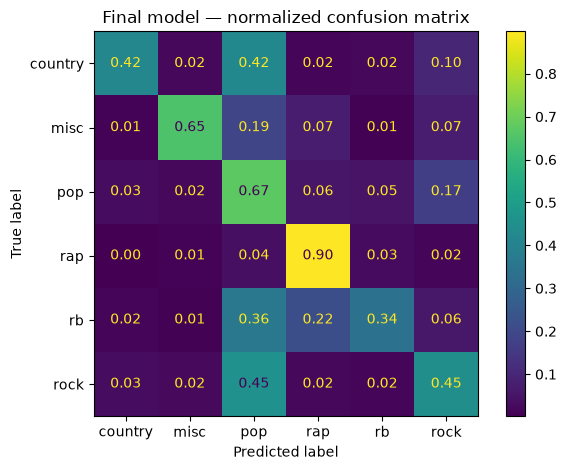

In [21]:
ConfusionMatrixDisplay.from_predictions(
    holdout_df["tag"],
    holdout_predictions,
    labels=config.LABELS,
    normalize="true",
    values_format=".2f",
)

plt.title(
    "Final model — normalized confusion matrix"
)

plt.tight_layout()
plt.show()

## 12. Model interpretation

Because the final Linear SVM is a linear classifier, its learned coefficients can be inspected to understand which features are most strongly associated with each genre.

For each class, the features with the largest positive coefficients are those that most strongly push the decision function toward that genre.

This analysis is used as a qualitative diagnostic rather than as an additional model-selection step.

In [22]:
feature_names = (
    final_dev_model
    .named_steps["features"]
    .get_feature_names_out()
)

coefficients = (
    final_dev_model
    .named_steps["classifier"]
    .coef_
)

classes = (
    final_dev_model
    .named_steps["classifier"]
    .classes_
)


top_features = {}


for class_index, genre in enumerate(classes):

    top_indices = np.argsort(
        coefficients[class_index]
    )[-12:][::-1]

    top_features[genre] = (
        feature_names[
            top_indices
        ]
    )


pd.DataFrame(
    top_features
)

,country,misc,pop,rap,rb,rock
0,word__old,word__cant,word__sec_drop,word__sec_hook,word__baby,word__sec_solo
1,word__whiskey,word__aint,word__sec_prechorus,structure__log_words,word__ooh,word__sec_verse
2,word__truck,structure__log_words,word__sec_postchorus,word__verse,word__babe,word__sec_chorus
3,word__country,word__which,word__chorus,word__bitch,word__verse,word__fucking
4,word__town,word__wont,word__oh,word__sec_intro,word__yeah,word__sec_instrumental
5,word__heartaches,word__poem,word__cause,word__rap,word__feelings,word__sec_solo sec_verse
6,word__sec_verse,word__i cant,word__and,word__like,word__girl,word__sec_verse well
7,word__bar,word__yet,word__you,word__fuck,word__hook,word__sec_solo sec_chorus
8,word__instrumental,word__nor,word__love,word__shit,word__you been,word__burn
9,word__sec_chorus,word__or,word__sec_prechorus i,word__hook,word__sec_outro,word__well


### Feature interpretation

The highest-weighted features show several plausible genre-specific patterns.

`country` is associated with lexical cues such as `old`, `whiskey`, `truck`, `country`, and `town`, while `rb` is characterised by terms such as `baby`, `ooh`, `babe`, `feelings`, and `girl`.

`rap` contains particularly distinctive lexical and structural signals, including `sec_hook`, `verse`, `rap`, and several genre-specific informal expressions. Song length (`log_words`) also appears among its strongest features, consistent with rap lyrics often containing comparatively long verses.

For `rock`, section markers such as `sec_solo`, `sec_verse`, `sec_chorus`, and `instrumental` receive high positive weights. `pop` is also strongly associated with structural markers such as `sec_prechorus`, `sec_postchorus`, and `sec_chorus`.

These results support two earlier modelling decisions: retaining section tokens and including lyrics-derived structural information. They also provide a plausible explanation for why `rap` is the most accurately classified genre in the holdout evaluation.

The coefficients should be interpreted as associations learned by the classifier rather than causal relationships between individual words and musical genre.

## 13. Final model training and Kaggle prediction

Model selection and evaluation are now complete.

The final configuration is retrained using **all available labelled training songs**, including the observations previously reserved for the holdout evaluation. This provides the classifier with the maximum amount of labelled information before predicting the official Kaggle test set.

The final model uses exactly the configuration selected before opening the holdout:

- balanced Linear SVM;
- `C=0.15`;
- sublinear word-level TF-IDF;
- word unigrams and bigrams;
- `min_df=10`;
- retained stopwords and section tokens;
- lyrics-derived structural features;
- no chi-square feature selection;
- no character n-grams.

No further model-selection decisions are made from the Kaggle predictions or leaderboard score.

In [23]:
final_full_model = Pipeline([
    (
        "features",
        make_word_features(
            sublinear_tf=True,
            include_structural=True,
            include_char=False,
        )
    ),
    (
        "classifier",
        LinearSVC(
            C=FINAL_C,
            class_weight="balanced",
            random_state=config.SEED,
        )
    ),
])


final_full_model.fit(
    train,
    train["tag"],
)


test_predictions = final_full_model.predict(
    test
)


print(
    "Training observations:",
    len(train)
)

print(
    "Test observations:",
    len(test)
)

print(
    "Predictions generated:",
    len(test_predictions)
)

print(
    "\nPredicted genre distribution:"
)

print(
    pd.Series(test_predictions)
    .value_counts(normalize=True)
    .reindex(config.LABELS)
    .fillna(0)
    .round(4)
)

Training observations: 134789
Test observations: 33742
Predictions generated: 33742

Predicted genre distribution:
country    0.0322
misc       0.0463
pop        0.4041
rap        0.2995
rb         0.0478
rock       0.1701
Name: proportion, dtype: float64


### Kaggle submission

The predictions are now converted into the format required by the Kaggle competition.

Before writing the file, the submission is validated against the official `sample_submission.csv` to ensure that:

- the number of predictions is correct;
- every test `id` is present exactly once;
- row order matches the official sample;
- all predicted labels belong to the six valid genres.

The resulting file corresponds exactly to the final model selected and trained above.

In [24]:
sample_submission = pd.read_csv(
    config.SAMPLE_SUBMISSION_CSV
)


prediction_df = pd.DataFrame({
    "id": test["id"].values,
    "tag": test_predictions,
})


# Basic validation
assert len(prediction_df) == len(test)
assert prediction_df["id"].is_unique
assert prediction_df["tag"].notna().all()
assert set(prediction_df["tag"]).issubset(
    set(config.LABELS)
)

assert set(prediction_df["id"]) == set(
    sample_submission["id"]
)


# Match Kaggle's required row order
final_submission = (
    sample_submission[["id"]]
    .merge(
        prediction_df,
        on="id",
        how="left",
        validate="one_to_one",
    )
)


# Final validation
assert len(final_submission) == len(
    sample_submission
)

assert final_submission["tag"].notna().all()


# Save
config.SUBMISSIONS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

submission_path = (
    config.SUBMISSIONS_DIR
    / "Group15_Version03.csv"
)

final_submission.to_csv(
    submission_path,
    index=False,
)


print(
    "Submission saved to:",
    submission_path
)

print(
    "Submission shape:",
    final_submission.shape
)

print(
    "Missing values:",
    final_submission.isna().sum().sum()
)

print(
    "Duplicated IDs:",
    final_submission["id"]
    .duplicated()
    .sum()
)

print(
    "Predicted genres:",
    sorted(
        final_submission["tag"].unique()
    )
)


display(
    final_submission.head()
)

Submission saved to: C:\Users\pedro\Desktop\Text Mining\Music-Genre-Identification\submissions\Group15_Version03.csv
Submission shape: (33742, 2)
Missing values: 0
Duplicated IDs: 0
Predicted genres: ['country', 'misc', 'pop', 'rap', 'rb', 'rock']


,id,tag
0,3230388,pop
1,3658643,rb
2,1270714,pop
3,3354312,rap
4,493974,pop


### Kaggle performance

The final lyrics-based classifier was submitted to the Kaggle competition as `Group15_Version03.csv`.

The public leaderboard results were:

| Submission | Public Macro F1 |
|---|---:|
| `Group15_Version01.csv` | 0.5510 |
| `Group15_Version03.csv` | **0.5728** |

The final model improves the previous public score by **0.0218 Macro F1**.

This improvement is consistent with the local validation results. The selected model achieved a mean 5-fold development Macro F1 of **0.5528** and an untouched holdout Macro F1 of **0.5584**, before reaching **0.5728** on the Kaggle public leaderboard.

The Kaggle score is slightly higher than the local estimates because the public leaderboard evaluates a different subset of unseen observations. The leaderboard was not used to modify the final model after submission.

## 14. Artist metadata diagnostic and hybrid extension

The primary model developed above uses only information derived from song lyrics.

As an additional diagnostic experiment, artist identity is evaluated as metadata because the dataset also provides the main artist associated with each song.

This extension is kept separate from the primary lyrics-only solution because artist identity may capture dataset-specific patterns rather than information contained in the lyrics themselves.

In [25]:
train_artist = pd.read_pickle(
    config.PROCESSED_DIR / "train_clean.pkl"
)[["id", "artist", "tag"]].copy()

test_artist = pd.read_pickle(
    config.PROCESSED_DIR / "test_clean.pkl"
)[["id", "artist"]].copy()


seen_artist_mask = test_artist["artist"].isin(
    train_artist["artist"]
)

seen_artist_share = seen_artist_mask.mean()


artist_genre_counts = (
    train_artist
    .groupby(["artist", "tag"])
    .size()
    .rename("count")
    .reset_index()
)


artist_song_counts = (
    train_artist
    .groupby("artist")
    .size()
    .rename("n_songs")
)


artist_dominance = (
    artist_genre_counts
    .groupby("artist")["count"]
    .max()
    .div(artist_song_counts)
)


repeated_artist_mask = artist_song_counts >= 2

repeated_artist_dominance = artist_dominance[
    repeated_artist_mask
]


print(
    "Test songs with artist seen in train:",
    f"{seen_artist_share:.1%}"
)

print(
    "Unique train artists:",
    train_artist["artist"].nunique()
)

print(
    "Unique test artists:",
    test_artist["artist"].nunique()
)

print(
    "Repeated train artists:",
    repeated_artist_mask.sum()
)

print(
    "Mean dominant-genre share among repeated artists:",
    f"{repeated_artist_dominance.mean():.1%}"
)

print(
    "Median dominant-genre share among repeated artists:",
    f"{repeated_artist_dominance.median():.1%}"
)

Test songs with artist seen in train: 62.1%
Unique train artists: 74886
Unique test artists: 26224
Repeated train artists: 23802
Mean dominant-genre share among repeated artists: 89.7%
Median dominant-genre share among repeated artists: 100.0%


### Artist signal

The diagnostic reveals a strong relationship between artist identity and genre.

Approximately **62.1%** of Kaggle test songs belong to artists already observed in the training data. Among training artists with at least two songs, the mean share of songs belonging to the artist's dominant genre is **89.7%**, with a median of **100%**.

This indicates that artist identity contains substantial predictive information. However, because the main task focuses on genre prediction from lyrics, artist metadata is evaluated separately as an experimental extension rather than replacing the lyrics-only model.

In [26]:
train["artist"] = train_artist["artist"].values
test["artist"] = test_artist["artist"].values

dev_df["artist"] = train.loc[
    dev_df.index,
    "artist"
]

holdout_df["artist"] = train.loc[
    holdout_df.index,
    "artist"
]

screen_df["artist"] = train.loc[
    screen_df.index,
    "artist"
]

In [27]:
def make_hybrid_features():
    return ColumnTransformer(
        transformers=[
            (
                "word",
                TfidfVectorizer(
                    token_pattern=r"(?u)\b\w+\b",
                    ngram_range=(1, 2),
                    min_df=10,
                    sublinear_tf=True,
                ),
                "clean",
            ),
            (
                "structure",
                MinMaxScaler(),
                STRUCTURAL_COLUMNS,
            ),
            (
                "artist",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                ["artist"],
            ),
        ],
        remainder="drop",
        sparse_threshold=1.0,
    )

### Hybrid lyrics + artist experiment

The selected lyrics representation is extended with a one-hot encoded artist feature.

The lyrics component remains unchanged: sublinear word-level TF-IDF with unigrams and bigrams plus structural features.

`OneHotEncoder(handle_unknown="ignore")` is used so that artists not observed during training do not cause errors.

The hybrid model is evaluated separately from the primary lyrics-only classifier.

In [28]:
# hybrid_model = Pipeline([
#     (
#         "features",
#         make_hybrid_features(),
#     ),
#     (
#         "classifier",
#         LinearSVC(
#             C=0.15,
#             class_weight="balanced",
#             random_state=config.SEED,
#         ),
#     ),
# ])


# hybrid_scores = cross_validate(
#     hybrid_model,
#     dev_df,
#     dev_df["tag"],
#     cv=screen_cv,
#     scoring={
#         "accuracy": "accuracy",
#         "macro_f1": "f1_macro",
#     },
#     n_jobs=1,
# )


# print(
#     "Hybrid accuracy:",
#     f"{hybrid_scores['test_accuracy'].mean():.4f}"
# )

# print(
#     "Hybrid Macro F1:",
#     f"{hybrid_scores['test_macro_f1'].mean():.4f}"
# )

# print(
#     "Macro F1 std:",
#     f"{hybrid_scores['test_macro_f1'].std():.4f}"
# )

### Hybrid cross-validation result

*This experiment was run during model development. The code is retained for transparency but is commented out in the final executable notebook.*

Adding artist identity substantially improves predictive performance.

The hybrid model achieved:

- Accuracy: **0.7398**
- Macro F1: **0.6578**

This represents a substantial improvement over the lyrics-only development results and suggests that artist identity contains strong complementary genre information.

### Hybrid holdout evaluation

The strong cross-validation improvement motivates an additional evaluation of the hybrid configuration on the holdout set.

The same classifier and lyrical representation are retained, with artist identity added through one-hot encoding.

In [31]:
hybrid_holdout_model = Pipeline([
    (
        "features",
        make_hybrid_features(),
    ),
    (
        "classifier",
        LinearSVC(
            C=0.15,
            class_weight="balanced",
            random_state=config.SEED,
        ),
    ),
])


hybrid_holdout_model.fit(
    dev_df,
    dev_df["tag"],
)


hybrid_holdout_predictions = (
    hybrid_holdout_model.predict(
        holdout_df
    )
)


hybrid_holdout_accuracy = accuracy_score(
    holdout_df["tag"],
    hybrid_holdout_predictions,
)

hybrid_holdout_macro_f1 = f1_score(
    holdout_df["tag"],
    hybrid_holdout_predictions,
    average="macro",
)


print(
    "Hybrid holdout accuracy:",
    f"{hybrid_holdout_accuracy:.4f}"
)

print(
    "Hybrid holdout Macro F1:",
    f"{hybrid_holdout_macro_f1:.4f}"
)

print()

print(
    classification_report(
        holdout_df["tag"],
        hybrid_holdout_predictions,
        labels=config.LABELS,
        digits=3,
        zero_division=0,
    )
)

Hybrid holdout accuracy: 0.7568
Hybrid holdout Macro F1: 0.6808

              precision    recall  f1-score   support

     country      0.693     0.579     0.631       693
        misc      0.781     0.686     0.730      1124
         pop      0.736     0.782     0.759     11120
         rap      0.871     0.917     0.893      7716
          rb      0.531     0.397     0.454      1240
        rock      0.655     0.585     0.618      5065

    accuracy                          0.757     26958
   macro avg      0.711     0.658     0.681     26958
weighted avg      0.751     0.757     0.752     26958



### Hybrid holdout results

The hybrid model achieves a holdout Macro F1 of **0.6808** and an accuracy of **0.7568**.

For comparison, the primary lyrics-only model achieved a holdout Macro F1 of **0.5584** and an accuracy of **0.6718**.

The largest improvements occur for previously difficult genres such as `country`, `rb`, and `rock`.

These results show that artist identity provides substantial complementary information. Nevertheless, the hybrid approach is interpreted separately from the primary lyrics-only classification task.

### Performance for seen and unseen artists

To better understand the source of the improvement produced by artist metadata, performance is evaluated separately for songs whose artists were already observed in the development data and songs associated with previously unseen artists.

If most of the improvement is concentrated among previously seen artists, this would indicate that the hybrid model benefits primarily from recognising recurring artist identities rather than from improved lyrical classification alone.

In [32]:
seen_in_dev = holdout_df["artist"].isin(
    dev_df["artist"]
)

for group_name, mask in {
    "Seen artists": seen_in_dev,
    "Unseen artists": ~seen_in_dev,
}.items():

    lyrics_f1 = f1_score(
        holdout_df.loc[mask, "tag"],
        holdout_predictions[mask],
        average="macro",
    )

    hybrid_f1 = f1_score(
        holdout_df.loc[mask, "tag"],
        hybrid_holdout_predictions[mask],
        average="macro",
    )

    print(group_name)
    print("Observations:", mask.sum())
    print(
        "Lyrics-only Macro F1:",
        f"{lyrics_f1:.4f}"
    )
    print(
        "Hybrid Macro F1:",
        f"{hybrid_f1:.4f}"
    )
    print(
        "Difference:",
        f"{hybrid_f1 - lyrics_f1:+.4f}"
    )
    print()

Seen artists
Observations: 15692
Lyrics-only Macro F1: 0.5677
Hybrid Macro F1: 0.7609
Difference: +0.1932

Unseen artists
Observations: 11266
Lyrics-only Macro F1: 0.5425
Hybrid Macro F1: 0.5132
Difference: -0.0293



### Seen versus unseen artist results

The effect of artist metadata is highly dependent on whether the artist has already been observed during training.

For songs associated with **seen artists**, the lyrics-only model achieves a Macro F1 of **0.5677**, while the hybrid model reaches **0.7609**, an improvement of **+0.1932**.

For songs associated with **unseen artists**, however, the lyrics-only model achieves **0.5425**, compared with **0.5132** for the hybrid model, corresponding to a decrease of **-0.0293**.

These results indicate that most of the hybrid model's improvement comes from recognising recurring artist identities. Artist metadata therefore provides a strong dataset-specific signal, but does not improve generalisation to previously unseen artists.

### Artist-only baseline

An artist-only classifier is also evaluated to quantify how much predictive information is available from artist identity without using the lyrics.

This diagnostic helps distinguish the contribution of artist metadata from the contribution of the textual representation.

In [33]:
artist_only_model = Pipeline([
    (
        "features",
        ColumnTransformer(
            transformers=[
                (
                    "artist",
                    OneHotEncoder(
                        handle_unknown="ignore"
                    ),
                    ["artist"],
                )
            ],
            remainder="drop",
        ),
    ),
    (
        "classifier",
        LinearSVC(
            C=0.15,
            class_weight="balanced",
            random_state=config.SEED,
        ),
    ),
])


artist_only_model.fit(
    dev_df,
    dev_df["tag"],
)


artist_only_predictions = artist_only_model.predict(
    holdout_df
)


artist_only_accuracy = accuracy_score(
    holdout_df["tag"],
    artist_only_predictions,
)


artist_only_macro_f1 = f1_score(
    holdout_df["tag"],
    artist_only_predictions,
    average="macro",
)


print(
    "Artist-only holdout accuracy:",
    f"{artist_only_accuracy:.4f}"
)

print(
    "Artist-only holdout Macro F1:",
    f"{artist_only_macro_f1:.4f}"
)

Artist-only holdout accuracy: 0.6264
Artist-only holdout Macro F1: 0.5762


### Artist-only results

The artist-only classifier achieves a holdout accuracy of **0.6264** and a Macro F1 of **0.5762**.

Notably, the artist-only Macro F1 is slightly higher than the **0.5584** obtained by the complete lyrics-only model on the same holdout set.

This confirms that artist identity alone contains substantial information about genre in this dataset.

However, the best overall performance is obtained by combining both sources of information: the hybrid lyrics + artist model achieves a holdout Macro F1 of **0.6808**.

Together with the seen-versus-unseen analysis, these results suggest that much of the metadata advantage is concentrated among artists already represented in the training data.

### Hybrid model training and Kaggle prediction

Following the local evaluation, the hybrid configuration is trained on the complete training dataset and used to generate an experimental Kaggle submission.

In [34]:
hybrid_full_model = Pipeline([
    (
        "features",
        make_hybrid_features(),
    ),
    (
        "classifier",
        LinearSVC(
            C=0.15,
            class_weight="balanced",
            random_state=config.SEED,
        ),
    ),
])


hybrid_full_model.fit(
    train,
    train["tag"],
)


hybrid_test_predictions = hybrid_full_model.predict(
    test
)


print(
    "Training observations:",
    len(train)
)

print(
    "Test observations:",
    len(test)
)

print(
    "Predictions generated:",
    len(hybrid_test_predictions)
)

print(
    "\nPredicted genre distribution:"
)

print(
    pd.Series(hybrid_test_predictions)
    .value_counts(normalize=True)
    .reindex(config.LABELS)
    .fillna(0)
    .round(4)
)

Training observations: 134789
Test observations: 33742
Predictions generated: 33742

Predicted genre distribution:
country    0.0235
misc       0.0374
pop        0.4315
rap        0.3043
rb         0.0348
rock       0.1684
Name: proportion, dtype: float64


In [35]:
sample_submission = pd.read_csv(
    config.SAMPLE_SUBMISSION_CSV
)


hybrid_prediction_df = pd.DataFrame({
    "id": test["id"].values,
    "tag": hybrid_test_predictions,
})


assert len(hybrid_prediction_df) == len(test)
assert hybrid_prediction_df["id"].is_unique
assert hybrid_prediction_df["tag"].notna().all()

assert set(
    hybrid_prediction_df["tag"]
).issubset(
    set(config.LABELS)
)


hybrid_submission = (
    sample_submission[["id"]]
    .merge(
        hybrid_prediction_df,
        on="id",
        how="left",
        validate="one_to_one",
    )
)


assert len(hybrid_submission) == len(
    sample_submission
)

assert hybrid_submission["tag"].notna().all()


hybrid_submission_path = (
    config.SUBMISSIONS_DIR
    / "Group15_Version04.csv"
)


hybrid_submission.to_csv(
    hybrid_submission_path,
    index=False,
)


print(
    "Submission saved to:",
    hybrid_submission_path.relative_to(ROOT)
)

print(
    "Submission shape:",
    hybrid_submission.shape
)

print(
    "Missing values:",
    hybrid_submission.isna().sum().sum()
)

print(
    "Duplicated IDs:",
    hybrid_submission["id"]
    .duplicated()
    .sum()
)

print(
    "Predicted genres:",
    sorted(
        hybrid_submission["tag"].unique()
    )
)

Submission saved to: submissions\Group15_Version04.csv
Submission shape: (33742, 2)
Missing values: 0
Duplicated IDs: 0
Predicted genres: ['country', 'misc', 'pop', 'rap', 'rb', 'rock']


### Hybrid Kaggle result

The experimental hybrid model was submitted as `Group15_Version04.csv`.

It achieved a public Kaggle Macro F1 of **0.6936**, substantially outperforming the lyrics-only `Group15_Version03.csv`, which achieved **0.5728**.

The improvement of **0.1208 Macro F1** is consistent with the substantial gain observed during local evaluation.

The result confirms that artist identity carries a strong predictive signal in this dataset. However, because artist metadata is not derived from the lyrics themselves, the hybrid model is reported as an experimental metadata extension rather than as a replacement for the primary lyrics-only solution.

## 15. Kaggle performance

Three Kaggle submissions were used to assess the evolution of the genre classification approach.

| Submission | Approach | Public Macro F1 |
|---|---|---:|
| Version01 | Initial lyrics-based model | 0.5510 |
| Version03 | Final lyrics-only model | 0.5728 |
| Version04 | Experimental lyrics + artist metadata model | 0.6936 |

The final lyrics-only model improves the initial Kaggle result from **0.5510** to **0.5728**.

The experimental addition of artist identity leads to a substantially larger improvement, reaching a public Macro F1 of **0.6936**.

This result is consistent with the local evaluation, where the hybrid model also substantially outperformed the lyrics-only classifier.

However, the two results should be interpreted separately. `Version03` represents the primary solution to the lyrics-based genre classification task, while `Version04` evaluates the additional predictive information available in artist metadata.

## 16. Genre Identification — Conclusion

This section investigated the prediction of six music genres from song lyrics using supervised text classification.

The modelling process compared several classifiers, including a dummy baseline, Multinomial Naive Bayes, Logistic Regression and Linear Support Vector Machines. Because the dataset is imbalanced and the competition uses Macro F1, class weighting was investigated and retained in the final classifier.

Several additional preprocessing and representation strategies were also evaluated. Removing stopwords or section tokens did not improve performance, while chi-squared feature selection reduced Macro F1. Sublinear word-level TF-IDF performed better than the standard representation, and structural lyric features provided a small additional improvement. Character n-grams and FastText embeddings were also tested but did not outperform the selected sparse representation.

The final lyrics-only configuration therefore combines:

- word-level TF-IDF with unigrams and bigrams;
- sublinear term frequency;
- structural lyric features;
- a class-balanced Linear SVM;
- `C = 0.15`.

On the development data, this configuration achieved a 5-fold cross-validated Macro F1 of **0.5528**. On the holdout set, it achieved an accuracy of **0.6718** and a Macro F1 of **0.5584**.

Performance varied considerably across genres. `rap` was the easiest class to identify, while `country` and `rb` remained substantially more difficult. The confusion matrix also showed considerable overlap between `pop` and `rock`, suggesting that some genres share substantial lyrical vocabulary.

The lyrics-only model was submitted to Kaggle as `Group15_Version03.csv` and achieved a public Macro F1 of **0.5728**, improving the initial submission score of **0.5510**.

### Artist metadata extension

A separate diagnostic revealed a strong artist effect in the dataset. Approximately **62.1%** of test songs were associated with artists already observed in the training data, while repeated artists had a mean dominant-genre share of **89.7%**.

Artist identity was therefore evaluated as an experimental metadata extension by combining one-hot encoded artist information with the selected lyrics representation.

The hybrid model achieved a holdout Macro F1 of **0.6808** and a public Kaggle Macro F1 of **0.6936**.

This substantial improvement demonstrates that artist identity contains strong predictive information in this dataset. Nevertheless, because artist metadata does not originate from the lyrics themselves, this result is reported separately from the primary lyrics-based solution.

Overall, the experiments show that classical sparse text representations combined with linear classifiers provide an effective and interpretable approach to music genre identification, while also revealing that non-textual metadata can strongly influence predictive performance.